In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import pydosert as PDRT
from pydosert.utils.plotting import overlay_mask_outline
from pydosert.objectives.losses import upper_penalty
from pathlib import Path
from IPython.display import clear_output

from pydosert.data import loaders
from pydosert.utils.utils import find_patient_paths

def load_patient(path):
    d = np.load(path)
    print(d.files)
    print(d['dose'].max())
    structures = {k[len("struct_"):]: torch.from_numpy(d[k]) for k in d.files if k.startswith("struct_")}
    return PDRT.Patient(
        attenuation_tensor=torch.from_numpy(d["density"]) if "density" in d else None,
        ct_tensor=None if "density" in d else torch.from_numpy(d["ct"]),
        structures=structures,
        dose=torch.from_numpy(d["dose"]) if "dose" in d else None,
        resolution=tuple(d["resolution"]),
        number_of_fractions=int(d["number_of_fractions"]),
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32
opt_patient = load_patient("CPPP_IMRT_patient.npz").to(dtype)   # float32 density, bool masks
#print(opt_patient.structures.keys())
#print(opt_patient.structures)
#print(opt_patient)

['ct', 'resolution', 'number_of_fractions', 'density', 'dose', 'struct_Avoid1', 'struct_Avoid2', 'struct_Body', 'struct_Center']
2.5651617


In [3]:
#SUPPOSEDLY THERE IS A #BUG IN THE FETCH_PLAN_DATA FUNCTION, THIS BELOW PATCHES IT SO THAT A SOURCE TO SURFACE DISTANCE ISNT REQUIRED FOR EVERY CONTROL POINT. THE PARSER EXPECTS THIS BUT IT IS NOT WRITTEN INTO THE DICOM FILE FOR WHATEVER REASON.

import math
import pydicom
from pydosert.data.beam import Beam

def fetch_plan_data_tolerant(plan_path):
    """Drop-in for pydosert's fetch_plan_data: handles control points without
    SourceToSurfaceDistance and clips the MLC leaves to the ASYMX jaws."""
    ds = pydicom.dcmread(str(plan_path))
    fg = ds.FractionGroupSequence[0]
    n_frac = int(fg.NumberOfFractionsPlanned)
    metersets = {str(rb.ReferencedBeamNumber): float(rb.BeamMeterset)
                 for rb in fg.ReferencedBeamSequence if hasattr(rb, "BeamMeterset")}

    params = {}
    for beam in ds.BeamSequence:
        mu_tot = metersets.get(str(beam.BeamNumber))
        if mu_tot is None:
            continue
        gantry = coll = 0.0
        ssd = iso = None
        jaw_x = jaw_y = leaves = None
        old_mu, beams = 0.0, []
        for cp in beam.ControlPointSequence:   # later CPs only carry what changes
            if cp.get("GantryAngle") is not None:             gantry = float(cp.GantryAngle)
            if cp.get("BeamLimitingDeviceAngle") is not None: coll = float(cp.BeamLimitingDeviceAngle)
            if cp.get("SourceToSurfaceDistance") is not None: ssd = float(cp.SourceToSurfaceDistance)
            if cp.get("IsocenterPosition") is not None and iso is None:
                ip = cp.IsocenterPosition
                iso = (float(ip[2]), float(ip[1]), float(ip[0]))
            for s in cp.get("BeamLimitingDevicePositionSequence", []):
                p = np.array([float(v) for v in s.LeafJawPositions])
                if s.RTBeamLimitingDeviceType in ("ASYMX", "X"):   jaw_x = p
                elif s.RTBeamLimitingDeviceType in ("ASYMY", "Y"): jaw_y = p
                elif s.RTBeamLimitingDeviceType == "MLCX":
                    leaves = np.stack([p[: len(p) // 2], p[len(p) // 2:]], 1)

            mu_val = mu_tot * float(cp.CumulativeMetersetWeight)
            beams.append(Beam(
                gantry_angle=math.radians(gantry),
                collimator_angle=math.radians(coll),
                ssd=ssd,
                mu=torch.from_numpy(np.array(mu_val - old_mu)),
                leaf_positions=torch.from_numpy(np.clip(leaves, jaw_x[0], jaw_x[1])),
                jaw_positions=torch.from_numpy(jaw_y.copy()),
                field_size=(400, 400),
                sid=float(beam.SourceAxisDistance),
                iso_center=iso,
            ))
            old_mu = mu_val
        if beams:
            params[f"{ds.SOPInstanceUID}_{beam.BeamNumber}"] = (beams, n_frac)
    return params

# load_dicom calls the name imported into the loaders module, so patch it there
loaders.fetch_plan_data = fetch_plan_data_tolerant

In [4]:
# This makes the dose calculation not take forever
from pydosert.layers.BeamWiseConvolutionalLayer import BeamWiseConvolutionalLayer

def _fft_beamwise_conv(self, fluence_vol, kernels, chunk=256):
    """FFT equivalent of BeamWiseConvolutionalLayer.forward (grouped conv2d, padding='same')."""
    BG, D, H, W, _ = fluence_vol.shape
    kH, kW = kernels.shape[0], kernels.shape[1]
    x = fluence_vol.reshape(BG * D, H, W)
    k = kernels.permute(2, 3, 0, 1).reshape(BG * D, kH, kW).flip(-2, -1)  # conv2d is a correlation
    fh, fw = H + kH - 1, W + kW - 1
    ph, pw = (kH - 1) // 2, (kW - 1) // 2
    parts = []
    for s in range(0, BG * D, chunk):
        e = min(s + chunk, BG * D)
        y = torch.fft.irfft2(torch.fft.rfft2(x[s:e], s=(fh, fw)) * torch.fft.rfft2(k[s:e], s=(fh, fw)),
                             s=(fh, fw))
        parts.append(y[:, ph:ph + H, pw:pw + W])
    return torch.cat(parts).view(BG, D, H, W, 1)

_original_conv_forward = BeamWiseConvolutionalLayer.forward     # kept so you can undo it
BeamWiseConvolutionalLayer.forward = _fft_beamwise_conv

#To go back to the stock convolution:

#BeamWiseConvolutionalLayer.forward = _original_conv_forward

In [5]:
S = opt_patient.structures
opt_patient.add_mask("External", S["Body"])                      # the full phantom
opt_patient.add_mask("Body", S["External"] & ~(S["Center"] | S["Avoid1"] | S["Avoid2"]),
                     overwrite=True)                             # body minus the other structures

colors = {
    "External": "orange",
    "Body": "purple",
    "Center": "yellow",
    "Avoid1": "green",
    "Avoid2": "blue",
}

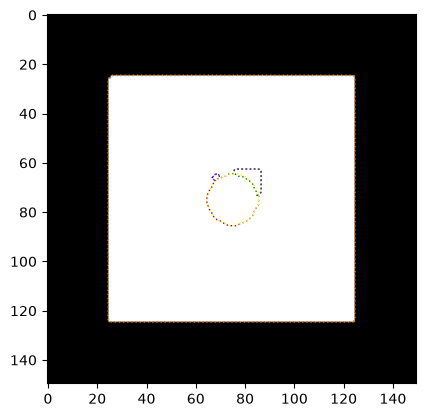

In [6]:
slice_idx = 50
plt.imshow(opt_patient.density_image.cpu().numpy()[slice_idx], cmap="gray")
for struct_name, mask in opt_patient.structures.items():
    overlay_mask_outline(mask.cpu().numpy()[slice_idx], color=colors[struct_name], sigma = 0.5) #sigma controls a gaussian blur mask on the exact voxels, 2.0 is default

In [7]:
patient_dir = 'CPPP-IMRT/'

ct_folder, rtplan_path, rtdose_path, rtstruct_path = find_patient_paths(patient_dir)
patient, beam_sequences = loaders.load_dicom(
            ct_folder=ct_folder,
            dose_path=rtdose_path,
            plan_path=rtplan_path,
            struct_path=rtstruct_path,
            # new_spacing=(3, 3, 3),
            struct_names=["Avoid1", "Avoid2", "Body", "Center"],
            use_delivery=True,
            device = device #This is necessary if there is no GPU
            )
patient = patient.to(device).to(dtype) # This line is required for type matching in the dose engine
print(patient.structures.keys())

body = patient.structures["Body"]
BODY_RED = 1.0034 #Changing the electron density from air (0.0012) to water (1.0034)
density = torch.where(body, BODY_RED, 0.0012).to(dtype)

beam_sequence = beam_sequences[0] # This is the number of mus per beam

dict_keys(['Avoid1', 'Avoid2', 'Body', 'Center'])


In [8]:
opt_patient = opt_patient.to(device).to(dtype)
S = opt_patient.structures

machine_config = PDRT.MachineConfig(preset = 'tb3_test')

engine = PDRT.DoseEngine(
    machine_config=machine_config,
    dose_grid_spacing=tuple(opt_patient.resolution),
    dose_grid_shape=tuple(opt_patient.density_image.shape),
    beam_template=beam_sequence,
    auto_calibrate=True,
    kernel_size=151,
    beam_chunk_size=10,          # the fix for the crash(in memory)
    dtype=dtype,
    device=device,
)
engine.train()


# plot_overview needs a CT for the background; make one from the density (plotting only)
plot_patient = PDRT.Patient(
    ct_tensor=(opt_patient.density_image - 1.0) * 1000.0,   # ~0 HU inside the phantom, ~-1000 HU outside
    structures=opt_patient.structures,
    dose=opt_patient.dose,
    resolution=opt_patient.resolution,
    number_of_fractions=opt_patient.number_of_fractions,
)

In [9]:
from pydosert.utils.plotting import plot_overview
def plot_overview_readable(patient, dose_pred=None, n_ticks=5, **kwargs):
    """plot_overview with a legible error colour bar: about n_ticks rounded, symmetric tick labels
    instead of the default labels at the contour levels, which overlap."""
    show = plt.show
    plt.show = lambda *a, **k: None          # plot_overview calls plt.show() itself; hold it until the ticks are fixed
    try:
        plot_overview(patient, dose_pred=dose_pred, **kwargs)
    finally:
        plt.show = show
    fig = plt.gcf()
    # The error colour bar is an inset axes of the bottom error panel, so it is not in fig.axes
    # itself: look through each axes' child (inset) axes as well.
    for ax in fig.axes:
        for cax in [ax, *ax.child_axes]:
            if cax.get_xlabel() == "Prediction - reference (Gy)":
                lo, hi = cax.get_xlim()
                v = max(abs(lo), abs(hi))
                ticks = MaxNLocator(nbins=n_ticks + 1, symmetric=True).tick_values(-v, v)
                ticks = ticks[np.abs(ticks) <= v * (1 + 1e-9)]          # keep only ticks inside the bar
                cbar = getattr(cax, "_colorbar", None)
                (cbar.set_ticks if cbar is not None else cax.set_xticks)(ticks)
                cax.tick_params(labelsize=12)
                cax.set_xlabel("PyDoseRT − TPS (Gy, full course)")
#    plt.savefig('SGD-opt.pdf', dpi = 1200)
    plt.show()
def plot_progress(epoch, raw_losses, dose_pred):
    clear_output(wait = True)
    print(f"Epoch {epoch}: {[str(np.round(loss.item(), 3))for loss in raw_losses]}")
    plot_overview(plot_patient, dose_pred = dose_pred)


PDRT dose of TPS plan: max 79.43 Gy over 25 fractions (TPS max 64.13 Gy)


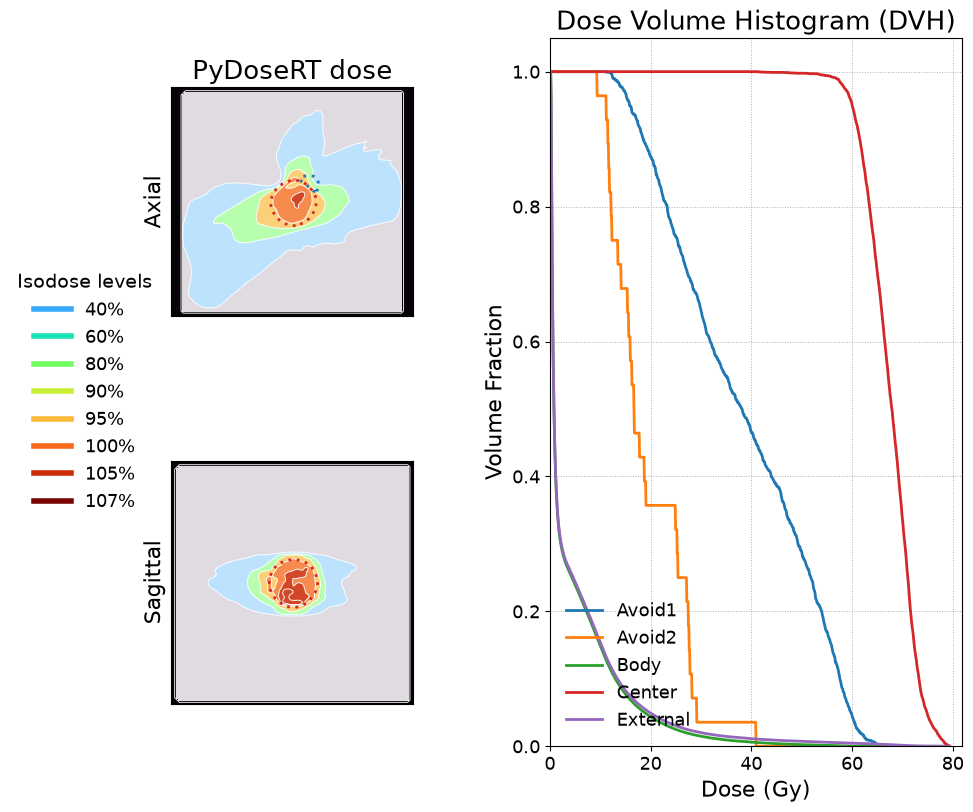

In [10]:
# PDRT dose of the original TPS plan (leaf, jaw and MU values as read from the RT Plan, no optimization)
# Needs only the cells up to and including the engine / plot_patient cell; no optimization cells.
from dataclasses import replace
from pydosert.utils.plotting import plot_overview

n_fx = opt_patient.number_of_fractions
tps_plan = replace(
    beam_sequence,
    leaf_positions=beam_sequence.leaf_positions.to(device, dtype),
    jaw_positions=beam_sequence.jaw_positions.to(device, dtype),
    mus=beam_sequence.mus.to(device, dtype),
)

with torch.no_grad():
    pdrt_dose_fx = engine.compute_dose(tps_plan, density_image=opt_patient.density_image)[0]   # Gy per fraction
    pdrt_dose_fx = torch.where(S["External"], pdrt_dose_fx, 0.0)                               # same masking as the optimizer

print(f"PDRT dose of TPS plan: max {pdrt_dose_fx.max() * n_fx:.2f} Gy over {n_fx} fractions "
      f"(TPS max {opt_patient.dose.max() * n_fx:.2f} Gy)")

# Plot only the PDRT dose: a copy of plot_patient without the TPS dose attached
pdrt_only = PDRT.Patient(
    ct_tensor=plot_patient._ct_tensor,
    structures=opt_patient.structures,
    dose=None,
    resolution=opt_patient.resolution,
    number_of_fractions=n_fx,
)
plot_overview(pdrt_only, dose_pred=pdrt_dose_fx)

# To see it next to the TPS dose (plus a PDRT - TPS difference column), use instead:
#plot_overview(plot_patient, dose_pred=pdrt_dose_fx)

median TPS/PDRT in high-dose region: 1.000  ->  calibration_mu 123.4 -> 123.4 MU
Avoid1    mean TPS  31.79 / PDRT  31.28   D95  13.48 /  13.01   D2  51.20 /  50.40   max  55.47 /  55.00
Avoid2    mean TPS  18.89 / PDRT  15.89   D95  11.56 /   9.23   D2  31.97 /  28.29   max  37.30 /  33.46
Body      mean TPS   2.90 / PDRT   3.36   D95   0.15 /   0.20   D2  21.38 /  22.17   max  56.28 /  58.71
Center    mean TPS  55.18 / PDRT  55.35   D95  49.33 /  49.15   D2  62.00 /  62.97   max  64.13 /  65.02
External  mean TPS   3.18 / PDRT   3.63   D95   0.15 /   0.20   D2  24.11 /  24.68   max  64.13 /  65.02


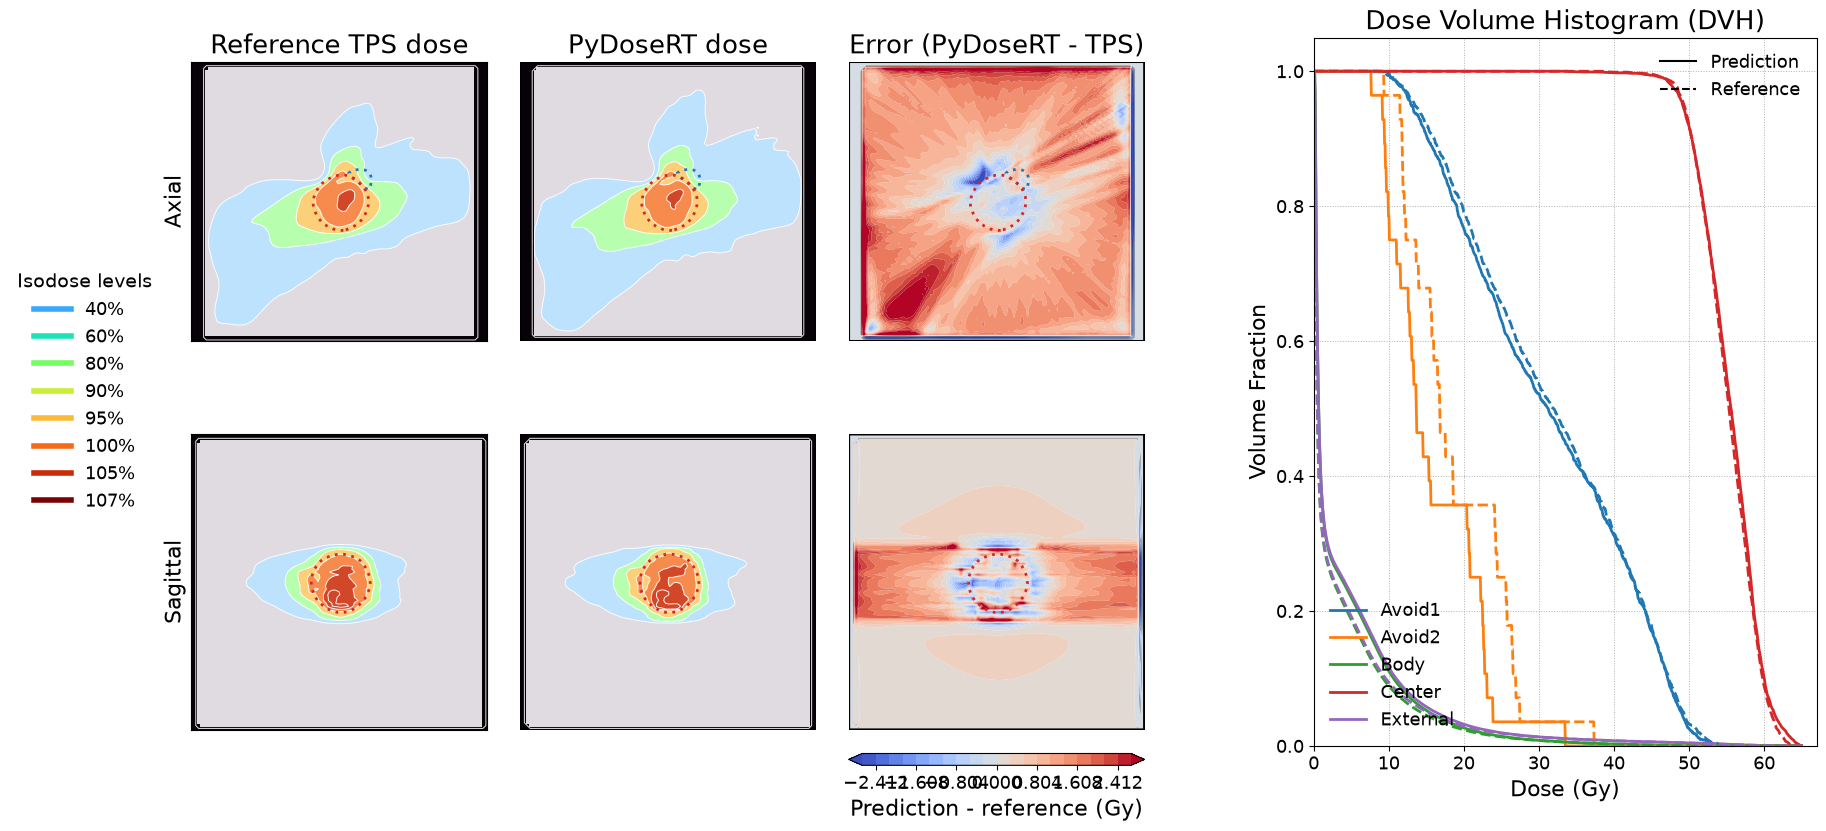

In [14]:
# Match PDRT's absolute dose calibration to the TPS, then recompute and compare.
# pydosert's calibrate() sets the engine so that `calibration_mu` MU gives 1 Gy at 10 cm depth
# (10x10 field, water, isocentric). The tb3_test preset uses 101 MU; a standard 6 MV TrueBeam
# (1 cGy/MU at dmax, SSD 100) needs roughly 123 MU for that, so PDRT comes out ~20% hot.
# Here the factor is measured from the doses instead of assumed. Run after the cell above.

tps_fx = opt_patient.dose.to(device)                                  # TPS, Gy per fraction
hi = S["External"] & (tps_fx >= 0.5 * tps_fx.max())                   # high-dose region only
scale = torch.median(tps_fx[hi] / pdrt_dose_fx[hi].clamp_min(1e-6)).item()

current_cal_mu = globals().get("current_cal_mu", machine_config.calibration_mu)
new_cal_mu = 123.4 #current_cal_mu / scale                                   # dose per MU is proportional to 1 / calibration_mu
print(f"median TPS/PDRT in high-dose region: {scale:.3f}  ->  calibration_mu {current_cal_mu:.1f} -> {new_cal_mu:.1f} MU")

engine.calibrate(calibration_mu=new_cal_mu, verbose=False)            # rescales every later compute_dose call
current_cal_mu = new_cal_mu

with torch.no_grad():
    pdrt_dose_fx = engine.compute_dose(tps_plan, density_image=opt_patient.density_image)[0]
    pdrt_dose_fx = torch.where(S["External"], pdrt_dose_fx, 0.0)

# Per-structure comparison, full course (Gy)
for name, mask in S.items():
    t, p = tps_fx[mask] * n_fx, pdrt_dose_fx[mask] * n_fx
    q = lambda d, x: torch.quantile(d.float(), x).item()
    print(f"{name:8s}  mean TPS {t.mean():6.2f} / PDRT {p.mean():6.2f}   "
          f"D95 {q(t, .05):6.2f} / {q(p, .05):6.2f}   D2 {q(t, .98):6.2f} / {q(p, .98):6.2f}   "
          f"max {t.max():6.2f} / {p.max():6.2f}")

plot_overview(plot_patient, dose_pred=pdrt_dose_fx)

isocentre dose:  TPS 2.3946 Gy  PDRT 2.3300 Gy  ratio 0.9730
max dose:  TPS 2.5652 Gy  PDRT 2.6007 Gy  ratio 1.0139
>50% isodose region: mean diff +0.17%  mean |diff| 1.35%  max |diff| 10.40%


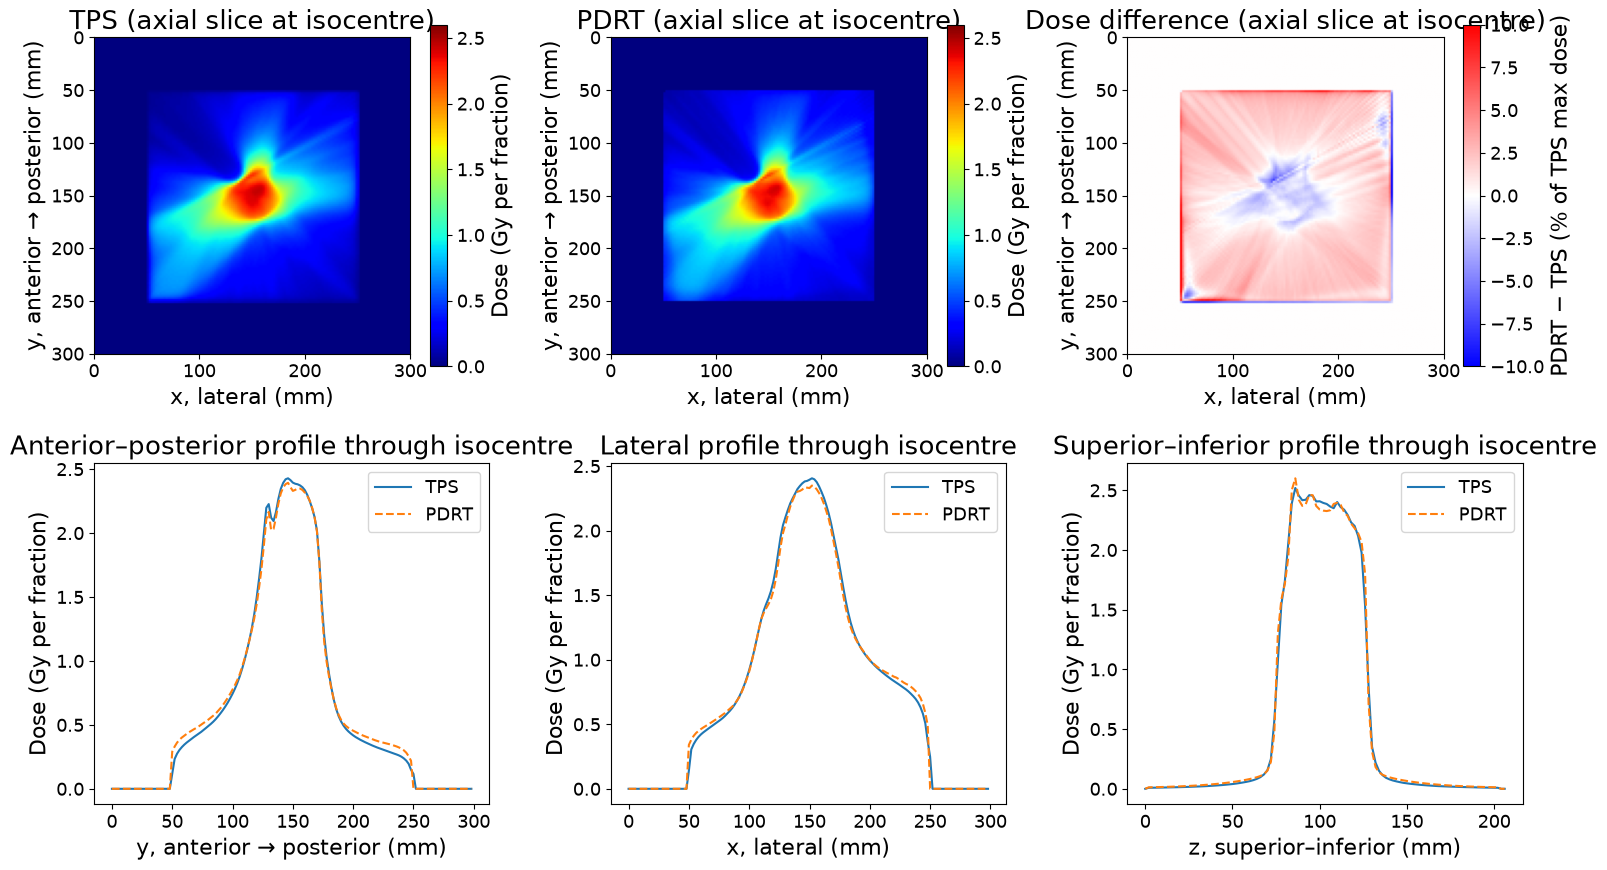

In [12]:
# Dose distribution, TPS vs PDRT for the TPS plan (after recalibration). Same as static.ipynb.
# Run after the recalibration cell above. Doses in Gy per fraction.
P = pdrt_dose_fx.cpu().numpy()
T = tps_fx.cpu().numpy()
res = np.array(opt_patient.resolution, dtype=float)                       # (z, y, x) mm

# Isocentre voxel, as in static.ipynb. If the plan's isocentre does not land inside this grid
# (the npz grid can have a different origin than the DICOM one), fall back to the centre of the target.
iso_vox = np.rint(np.array(beam_sequence.iso_center, dtype=float) / res).astype(int)
if np.all((iso_vox >= 0) & (iso_vox < np.array(T.shape))):
    zi, yi, xi = iso_vox
    point_name = "isocentre"
else:
    zi, yi, xi = np.rint(np.argwhere(S["Center"].cpu().numpy()).mean(axis=0)).astype(int)
    point_name = "Center centroid"
    print(f"Plan isocentre {tuple(iso_vox)} is outside the grid {T.shape}; using the Center centroid {(zi, yi, xi)}")

diff = (P - T) / T.max() * 100                                             # % of TPS max
hi = T > 0.5 * T.max()
print(f"{point_name} dose:  TPS {T[zi, yi, xi]:.4f} Gy  PDRT {P[zi, yi, xi]:.4f} Gy  ratio {P[zi, yi, xi] / T[zi, yi, xi]:.4f}")
print(f"max dose:  TPS {T.max():.4f} Gy  PDRT {P.max():.4f} Gy  ratio {P.max() / T.max():.4f}")
print(f">50% isodose region: mean diff {diff[hi].mean():+.2f}%  mean |diff| {np.abs(diff[hi]).mean():.2f}%  max |diff| {np.abs(diff[hi]).max():.2f}%")

z_mm, y_mm, x_mm = (np.arange(n) * r for n, r in zip(T.shape, res))
extent = [0, T.shape[2] * res[2], T.shape[1] * res[1], 0]                 # axial slices in mm (x across, y down)
vmax = max(T.max(), P.max())
dose_label = "Dose (Gy per fraction)"

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, img, title in [(ax[0, 0], T[zi], f"TPS (axial slice at {point_name})"),
                      (ax[0, 1], P[zi], f"PDRT (axial slice at {point_name})")]:
    im = a.imshow(img, vmin=0, vmax=vmax, cmap="jet", extent=extent)
    fig.colorbar(im, ax=a, label=dose_label)
    a.set_title(title)
im = ax[0, 2].imshow(diff[zi], cmap="bwr", vmin=-10, vmax=10, extent=extent)
fig.colorbar(im, ax=ax[0, 2], label="PDRT − TPS (% of TPS max dose)")
ax[0, 2].set_title(f"Dose difference (axial slice at {point_name})")
for a in ax[0]:
    a.set_xlabel("x, lateral (mm)")
    a.set_ylabel("y, anterior → posterior (mm)")

# A VMAT arc has no single beam axis, so these are straight profiles through the point along each axis
for a, axis, prof_T, prof_P, title, xlabel in [
    (ax[1, 0], y_mm, T[zi, :, xi], P[zi, :, xi], f"Anterior–posterior profile through {point_name}", "y, anterior → posterior (mm)"),
    (ax[1, 1], x_mm, T[zi, yi, :], P[zi, yi, :], f"Lateral profile through {point_name}", "x, lateral (mm)"),
    (ax[1, 2], z_mm, T[:, yi, xi], P[:, yi, xi], f"Superior–inferior profile through {point_name}", "z, superior–inferior (mm)"),
]:
    a.plot(axis, prof_T, label="TPS"); a.plot(axis, prof_P, "--", label="PDRT")
    a.set_title(title); a.set_xlabel(xlabel); a.set_ylabel(dose_label); a.legend()
plt.tight_layout()

plt.savefig('IMRT-dist.pdf', dpi=1200)
plt.show()

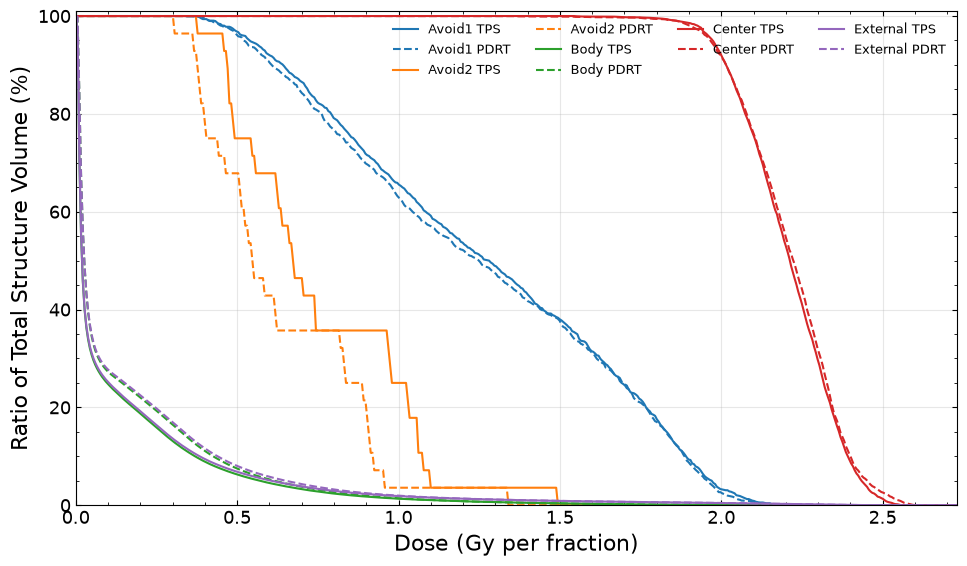

Dose statistics (Gy per fraction); Dx = minimum dose to the hottest x% of the structure


volume (cc)   mean    min    max    D98    D95    D50     D2
structure source                                                              
Avoid1    TPS          10.208  1.271  0.344  2.219  0.462  0.539  1.279  2.048
          PDRT         10.208  1.251  0.365  2.200  0.454  0.521  1.249  2.016
Avoid2    TPS           0.224  0.755  0.374  1.492  0.420  0.462  0.672  1.279
          PDRT          0.224  0.636  0.306  1.338  0.338  0.369  0.547  1.131
Body      TPS        8028.520  0.116  0.002  2.251  0.005  0.006  0.019  0.855
          PDRT       8028.520  0.134  0.005  2.349  0.007  0.008  0.026  0.887
Center    TPS          37.504  2.207  1.543  2.565  1.927  1.973  2.212  2.480
          PDRT         37.504  2.214  1.354  2.601  1.903  1.966  2.223  2.519
External  TPS        8076.024  0.127  0.002  2.565  0.005  0.006  0.019  0.964
          PDRT       8076.024  0.145  0.005  2.601  0.007  0.008  0.027  0.987

PDRT vs TPS, % difference


,mean,min,max,D98,D95,D50,D2
structure,,,,,,,
Avoid1,-1.60,6.070000,-0.85,-1.910000,-3.490000,-2.310000,-1.55
Avoid2,-15.88,-18.260000,-10.30,-19.520000,-20.170000,-18.549999,-11.53
Body,15.89,111.120003,4.33,36.619999,34.580002,38.400002,3.70
Center,0.30,-12.300000,1.39,-1.250000,-0.370000,0.510000,1.57
External,14.42,111.120003,1.39,36.580002,34.599998,38.369999,2.39


In [13]:
import pandas as pd

# Dose distribution in each structure: cumulative DVHs and dose statistics, TPS vs PDRT (Gy per fraction).
# Same as the last cell of static.ipynb. External contains the other structures; Body is External minus them.
voxel_cc = float(np.prod(res)) / 1000.0
bins = np.linspace(0, 1.05 * max(T.max(), P.max()), 500)

def dvh(dose_in_struct):
    """Cumulative DVH: % of the structure volume receiving at least each dose in `bins`."""
    return np.array([(dose_in_struct >= b).mean() * 100 for b in bins])

def d_at(dose_in_struct, pct_volume):
    """D_x: minimum dose received by the hottest pct_volume % of the structure."""
    return np.percentile(dose_in_struct, 100 - pct_volume)

rows = []
fig, ax = plt.subplots(figsize=(10, 6))
for (name, mask), color in zip(S.items(), plt.cm.tab10.colors):
    m = mask.cpu().numpy()
    t, p = T[m], P[m]
    ax.plot(bins, dvh(t), color=color, label=f"{name} TPS")
    ax.plot(bins, dvh(p), color=color, linestyle="--", label=f"{name} PDRT")
    for src, d in (("TPS", t), ("PDRT", p)):
        rows.append({"structure": name, "source": src, "volume (cc)": m.sum() * voxel_cc,
                     "mean": d.mean(), "min": d.min(), "max": d.max(),
                     "D98": d_at(d, 98), "D95": d_at(d, 95), "D50": d_at(d, 50), "D2": d_at(d, 2)})
ax.set_xlabel("Dose (Gy per fraction)")
ax.set_ylabel("Ratio of Total Structure Volume (%)")
ax.set_xlim(0, bins[-1]); ax.set_ylim(0, 101); ax.grid(alpha=0.3)
ax.legend(ncol=4, fontsize=9, frameon=False)
plt.tight_layout()
plt.minorticks_on()
plt.tick_params(which='both', direction='in', right=True, top=True)

plt.savefig('IMRT-DVH.pdf', dpi=1200)
plt.show()

stats = pd.DataFrame(rows).set_index(["structure", "source"])
dose_cols = ["mean", "min", "max", "D98", "D95", "D50", "D2"]
diff_pct = (stats.xs("PDRT", level="source")[dose_cols] / stats.xs("TPS", level="source")[dose_cols] - 1) * 100
print("Dose statistics (Gy per fraction); Dx = minimum dose to the hottest x% of the structure")
display(stats.round(3))
print("PDRT vs TPS, % difference")
display(diff_pct.round(2))